**CHAPTER 7**
**CLUSTERING PADA DATA KOMENTAR TIKTOK**

Nama: Tabrizzi Aqlia
NIM: 25031554008

Pada Exercise 7 ini, saya menerapkan seluruh metode clustering (KMeans dan Hierarchical Clustering dengan metode Ward) pada hasil feature engineering dari Exercise 5 (One Hot Encoding, Bag of Words, TF-IDF, Word2Vec, dan FastText) yang berasal dari komentar TikTok hasil preprocessing Chapter 4. Pembahasan utama memakai TF-IDF, kemudian kelima representasi dibandingkan menggunakan silhouette score.

**Install & import**

In [1]:
!pip install -q gensim wordcloud

import warnings
warnings.filterwarnings(action='ignore')

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gensim.models
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from scipy.cluster.hierarchy import dendrogram, linkage
from wordcloud import WordCloud

**Ambil data hasil Chapter 4**

In [18]:
try:
    df = hasil_tiktok.copy()
except NameError:
    for path in ['hasil_tiktok.csv', 'sample_data/hasil_tiktok.csv']:
        if os.path.exists(path):
            df = pd.read_csv(path)
            print("Data dibaca dari:", path)
            break
    else:
        raise FileNotFoundError("hasil_tiktok.csv tidak ditemukan, upload dulu ke Colab")

df = df.dropna(subset=['prepro']).copy()
df['prepro'] = df['prepro'].astype(str).str.strip()
df = df[df['prepro'] != ''].reset_index(drop=True)

docs = df['prepro']
print("Jumlah komentar yang dipakai:", len(df))
df[['text_original', 'prepro']].head(1265)

Data dibaca dari: sample_data/hasil_tiktok.csv
Jumlah komentar yang dipakai: 1265


,text_original,prepro
0,AGUSTUS JAHAT.,agustus jahat
1,monyet nya gimana ya,monyet nya gimana
2,kondisi hewannya gimana termasuk ini?,kondisi hewan gimana masuk
3,"yaallah kasian banget hewan hewan disana, leka...",yaallah kasi banget hewan hewan sana lekas pul...
4,semoga cepat hujan ya kalimantan,moga cepat hujan kalimantan
...,...,...
1260,udah kaya di ajab allah gak sih,udah kaya ajab allah gak sih
1261,gua kena asap karna gua Kalimantan Barat,gua kena asap karna gua kalimantan barat
1262,di bakar,bakar
1263,yallah,yallah


**Bangun ulang One Hot, BoW, dan TF-IDF**

In [6]:
ohe_vec = CountVectorizer(binary=True)
D_ohe = ohe_vec.fit_transform(docs).toarray()

bow_vec = CountVectorizer()
D_bow = bow_vec.fit_transform(docs).toarray()

tfidf_vec = TfidfVectorizer()
D_tfidf = tfidf_vec.fit_transform(docs).toarray()
terms = tfidf_vec.get_feature_names_out()

print("One Hot :", D_ohe.shape)
print("BoW     :", D_bow.shape)
print("TF-IDF  :", D_tfidf.shape)

One Hot : (1265, 2986)
BoW     : (1265, 2986)
TF-IDF  : (1265, 2986)


**Bangun ulang Word2Vec dan FastText**

In [7]:
sentences = [t.split() for t in docs]

w2v_model = gensim.models.Word2Vec(
    sentences, min_count=1, vector_size=100, window=5, sg=0, epochs=50, seed=42
)
ft_model = gensim.models.FastText(
    sentences, min_count=1, vector_size=100, window=5,
    min_n=3, max_n=6, sg=1, epochs=50, seed=42
)

def doc_vector(tokens, wv):
    vecs = [wv[w] for w in tokens if w in wv]
    return np.mean(vecs, axis=0) if vecs else np.zeros(wv.vector_size)

X_w2v = np.array([doc_vector(t, w2v_model.wv) for t in sentences])
X_ft = np.array([doc_vector(t, ft_model.wv) for t in sentences])

print("Word2Vec:", X_w2v.shape)
print("FastText:", X_ft.shape)

Word2Vec: (1265, 100)
FastText: (1265, 100)


**1. KMeans Clustering (TF-IDF)**

Langkah pertama adalah menentukan jumlah klaster. Dua cara yang dipakai: elbow method (inertia) dan silhouette score untuk k = 2 sampai 8.

**Elbow dan silhouette untuk beberapa nilai k**

,k,Inertia,Silhouette
0,2,1235.184,0.0061
1,3,1225.592,0.0070
2,4,1220.662,0.0076
3,5,1213.237,0.0069
4,6,1206.659,0.0093
5,7,1204.330,0.0088
6,8,1196.859,0.0109


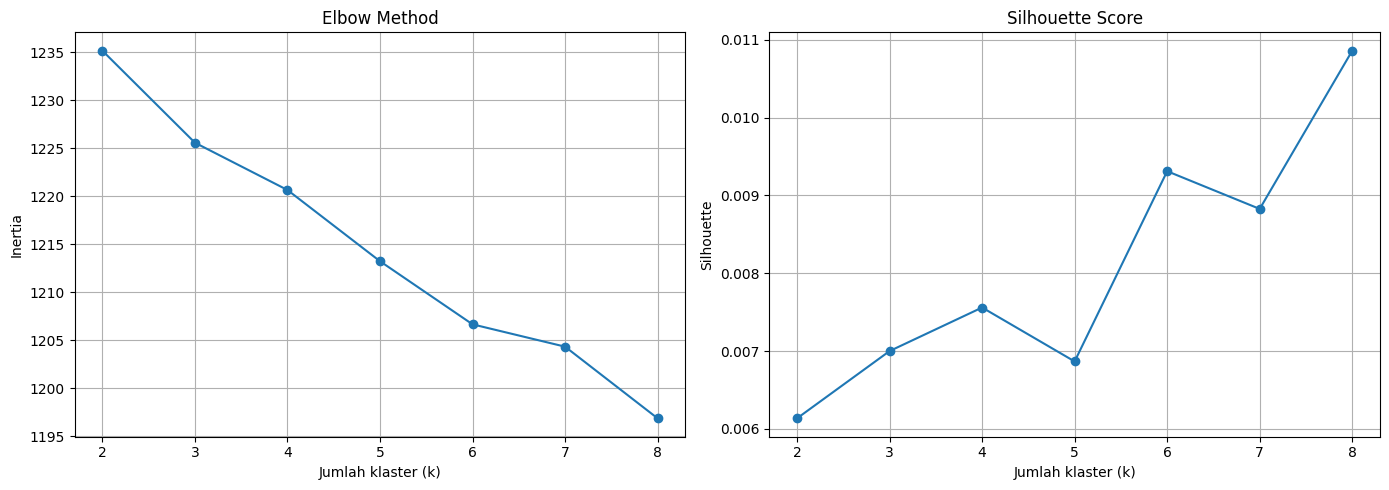

In [8]:
k_range = list(range(2, 9))
inertia, sil = [], []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=10, n_init=10).fit(D_tfidf)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(D_tfidf, km.labels_))

hasil_k = pd.DataFrame({
    'k': k_range,
    'Inertia': np.round(inertia, 3),
    'Silhouette': np.round(sil, 4)
})
display(hasil_k)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(k_range, inertia, marker='o')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('Jumlah klaster (k)')
axes[0].set_ylabel('Inertia')
axes[0].grid()

axes[1].plot(k_range, sil, marker='o')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Jumlah klaster (k)')
axes[1].set_ylabel('Silhouette')
axes[1].grid()

plt.tight_layout()
plt.show()

**KMeans dengan jumlah klaster yang dipilih**

Jumlah klaster ditetapkan 4, mengikuti contoh pada materi, agar hasil tiap klaster masih mudah ditafsirkan.

**Jalankan KMeans**

In [9]:
n_clusters = 4

kM = KMeans(n_clusters=n_clusters, random_state=10, n_init=10).fit(D_tfidf)
df['Kmeans_label'] = kM.labels_

print("Jumlah komentar per klaster (KMeans):")
display(df['Kmeans_label'].value_counts().sort_index().to_frame('Jumlah komentar'))

print("Silhouette score KMeans (TF-IDF):", round(silhouette_score(D_tfidf, kM.labels_, metric='euclidean'), 4))

Jumlah komentar per klaster (KMeans):


,Jumlah komentar
Kmeans_label,
0,138
1,136
2,117
3,874


Silhouette score KMeans (TF-IDF): 0.0076


**Kata dominan dan contoh komentar tiap klaster (KMeans)**

In [10]:
tfidf_df = pd.DataFrame(D_tfidf, columns=terms)

kata_km = pd.DataFrame({
    f'Klaster {c}': tfidf_df[df['Kmeans_label'] == c].mean()
                    .sort_values(ascending=False).head(10).index
    for c in range(n_clusters)
})
print("10 kata dominan tiap klaster (rata-rata TF-IDF tertinggi):")
display(kata_km)

for c in range(n_clusters):
    print(f"\n--- Contoh komentar Klaster {c} ---")
    for teks in df[df['Kmeans_label'] == c]['text_original'].head(3):
        print("-", str(teks)[:150])

10 kata dominan tiap klaster (rata-rata TF-IDF tertinggi):


,Klaster 0,Klaster 1,Klaster 2,Klaster 3
0,nya,bakar,allah,kak
1,perintah,hutan,moga,yg
2,monyet,yg,hujan,kalimantan
3,bukan,lahan,cepat,aku
4,yg,kalimantan,turun,apa
5,udah,sawit,kalimantan,aja
6,hewan,sengaja,lindung,gak
7,ga,apa,sana,ga
8,presiden,orang,pulih,udah
9,gimana,kemarau,segera,iya



--- Contoh komentar Klaster 0 ---
- monyet nya gimana ya
- Aku kasian sama hewan2 nya
- hewan hewan nya gimna yaa🥺

--- Contoh komentar Klaster 1 ---
- aku bisa bayangin sesesak apa dada kalian, seperih apa mata kalian😭. jahat banget yang bakar hutan. semoga Allah membalas dengan balasan paling perih 
- Nextnya kita pantau terus, akan dijadikan lahan hijau hutan lagi apa jadi kebun sawit😡
- hanya di Indonesia punya hutan beribu2 hektar tapi tidak punya satupun pesawat pemadam kebakaran

--- Contoh komentar Klaster 2 ---
- semoga cepat hujan ya kalimantan
- semoga kalimantan cepat pulih"aminnnn🤲
- ya Allah semoga cepat sembuh Kalimantan

--- Contoh komentar Klaster 3 ---
- AGUSTUS JAHAT.
- kondisi hewannya gimana termasuk ini?
- yaallah kasian banget hewan hewan disana, lekas pulih kalimantanku 🥺


**Word Cloud KMeans**

**Word cloud tiap klaster (KMeans)**

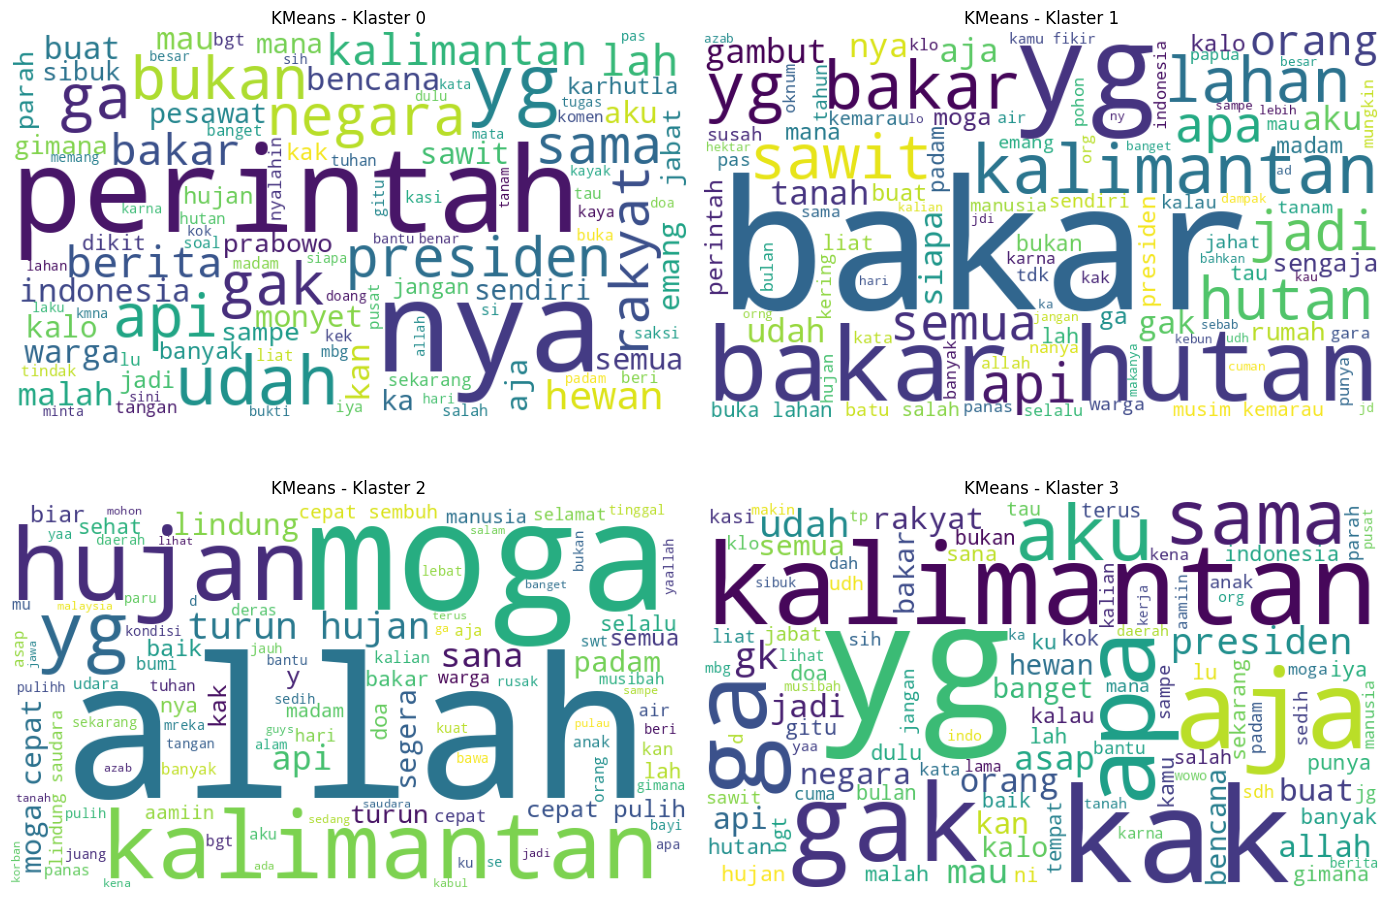

In [11]:
baris = int(np.ceil(n_clusters / 2))
fig, axes = plt.subplots(baris, 2, figsize=(14, 5 * baris))
axes = axes.ravel()

for c in range(n_clusters):
    teks = ' '.join(df[df['Kmeans_label'] == c]['prepro'])
    wc = WordCloud(background_color='white', max_words=100, width=700, height=400).generate(teks)
    axes[c].imshow(wc)
    axes[c].set_title(f'KMeans - Klaster {c}')
    axes[c].axis('off')

for ax in axes[n_clusters:]:
    ax.axis('off')

plt.tight_layout()
plt.show()

**2. Hierarchical Clustering (TF-IDF)**

Metode yang dipakai adalah Ward linkage dengan jarak Euclidean. Hasilnya divisualisasikan dengan dendrogram, lalu dipotong menjadi 4 klaster agar sebanding dengan KMeans.

**Dendrogram**

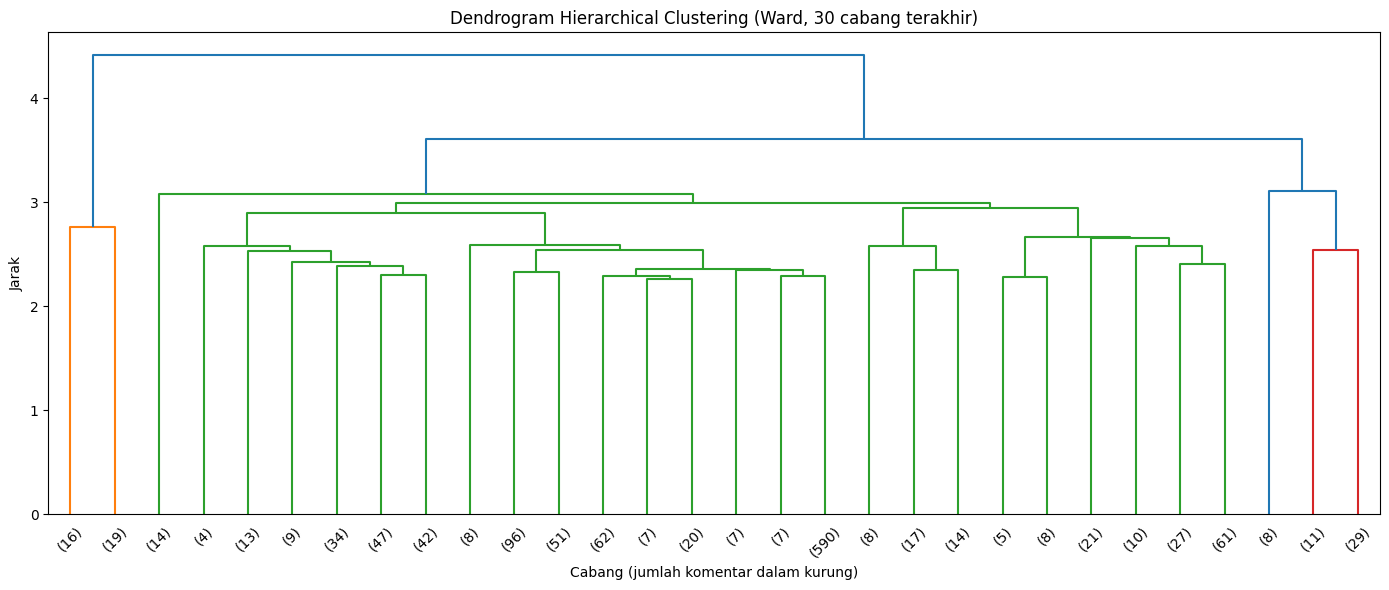

In [12]:
linkage_data = linkage(D_tfidf, method='ward', metric='euclidean')

plt.figure(figsize=(14, 6))
dendrogram(linkage_data, truncate_mode='lastp', p=30)
plt.title('Dendrogram Hierarchical Clustering (Ward, 30 cabang terakhir)')
plt.xlabel('Cabang (jumlah komentar dalam kurung)')
plt.ylabel('Jarak')
plt.tight_layout()
plt.show()

**Jalankan Hierarchical**

In [13]:
hierarchical = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward').fit(D_tfidf)
df['Ward_label'] = hierarchical.labels_

print("Jumlah komentar per klaster (Hierarchical):")
display(df['Ward_label'].value_counts().sort_index().to_frame('Jumlah komentar'))

print("Silhouette score Hierarchical (TF-IDF):", round(silhouette_score(D_tfidf, hierarchical.labels_, metric='euclidean'), 4))

Jumlah komentar per klaster (Hierarchical):


,Jumlah komentar
Ward_label,
0,1182
1,35
2,40
3,8


Silhouette score Hierarchical (TF-IDF): 0.0022


**Kata dominan dan contoh komentar tiap klaster (Hierarchical)**

In [14]:
kata_ward = pd.DataFrame({
    f'Klaster {c}': tfidf_df[df['Ward_label'] == c].mean()
                    .sort_values(ascending=False).head(10).index
    for c in range(n_clusters)
})
print("10 kata dominan tiap klaster (rata-rata TF-IDF tertinggi):")
display(kata_ward)

for c in range(n_clusters):
    print(f"\n--- Contoh komentar Klaster {c} ---")
    for teks in df[df['Ward_label'] == c]['text_original'].head(3):
        print("-", str(teks)[:150])

10 kata dominan tiap klaster (rata-rata TF-IDF tertinggi):


,Klaster 0,Klaster 1,Klaster 2,Klaster 3
0,bakar,cepat,allah,aamiin
1,yg,moga,lindung,allahumma
2,kak,hujan,selamat,yra
3,kalimantan,kalimantan,sana,yrb
4,nya,turun,yg,allah
5,perintah,allah,moga,rabbalalamin
6,aku,pulih,saudara,kunfayakun
7,apa,sembuh,swt,yaallah
8,udah,segera,beri,yaa
9,gak,pulihh,semua,orgutan



--- Contoh komentar Klaster 0 ---
- AGUSTUS JAHAT.
- monyet nya gimana ya
- kondisi hewannya gimana termasuk ini?

--- Contoh komentar Klaster 1 ---
- semoga cepat hujan ya kalimantan
- semoga kalimantan cepat pulih"aminnnn🤲
- ya Allah semoga cepat sembuh Kalimantan

--- Contoh komentar Klaster 2 ---
- Tahun ini kita di beri ujian bertubi2..ya Allah hamba bersaksi betapa dzolim nya mereka yg merusak kalimantan..semoga engkau memberi azab yg setimpal
- Semoga Kita di jauhkan dari Azab Allah akibat keserakahan manusia
- Semoga mereka dalam lindungan Allah SWT

--- Contoh komentar Klaster 3 ---
- Aamiin
- aamiin.. yrb 🤲🤲🤲
- Aamiin YRA 🤲


**Word Cloud Hierarchical**

**Word cloud tiap klaster (Hierarchical)**

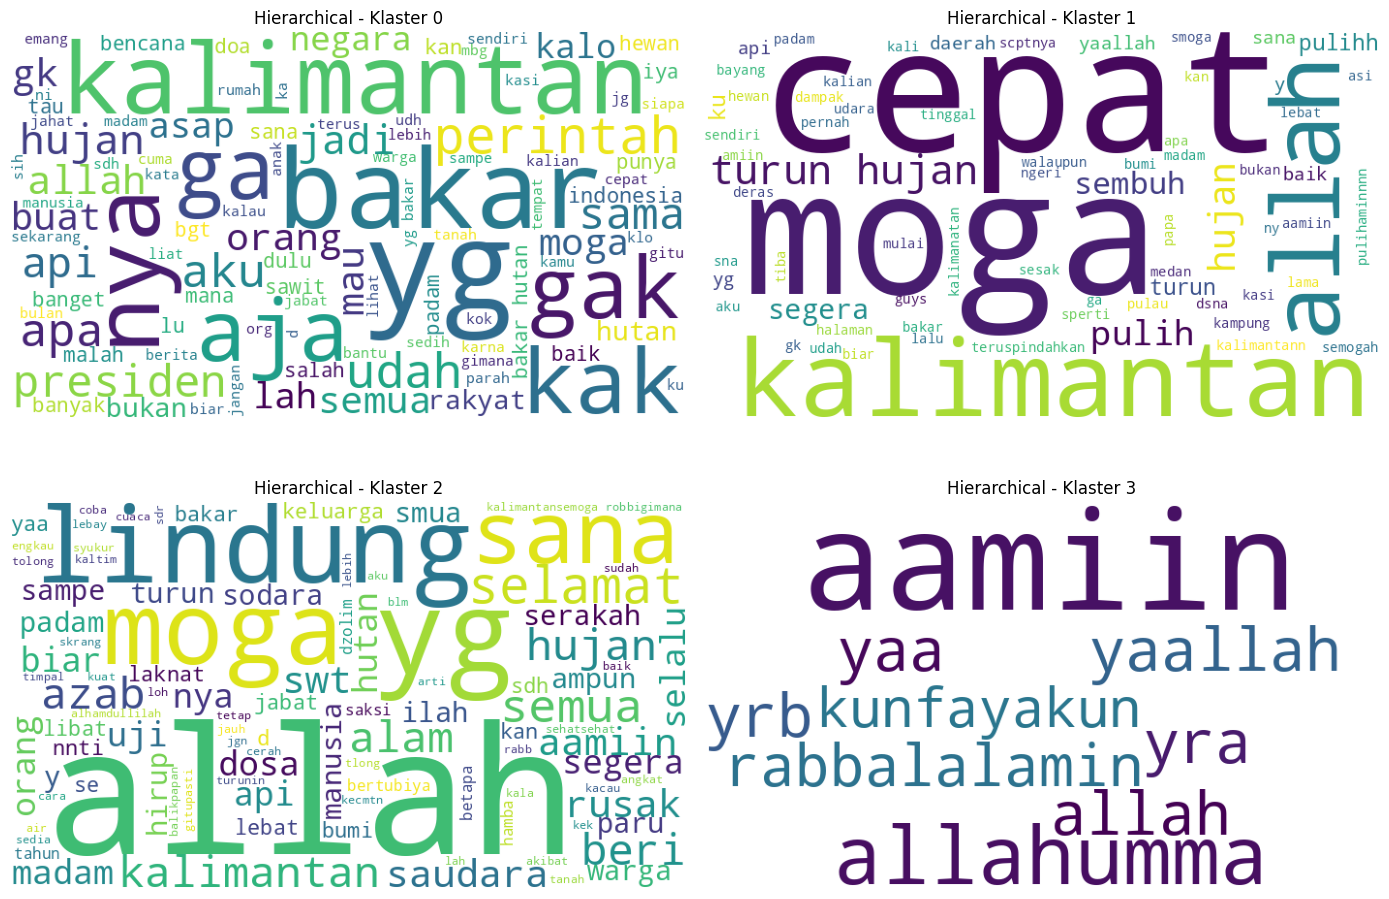

In [15]:
fig, axes = plt.subplots(baris, 2, figsize=(14, 5 * baris))
axes = axes.ravel()

for c in range(n_clusters):
    teks = ' '.join(df[df['Ward_label'] == c]['prepro'])
    wc = WordCloud(background_color='white', max_words=100, width=700, height=400).generate(teks)
    axes[c].imshow(wc)
    axes[c].set_title(f'Hierarchical - Klaster {c}')
    axes[c].axis('off')

for ax in axes[n_clusters:]:
    ax.axis('off')

plt.tight_layout()
plt.show()

**3. Perbandingan Seluruh Representasi Fitur**

KMeans dan Hierarchical diterapkan pada kelima hasil feature engineering Exercise 5 dengan jumlah klaster yang sama (4), lalu dibandingkan menggunakan silhouette score. Nilai silhouette berkisar -1 sampai 1; makin tinggi berarti klaster makin terpisah jelas.

**Silhouette semua representasi**

In [16]:
representasi = {
    'One Hot': D_ohe,
    'BoW': D_bow,
    'TF-IDF': D_tfidf,
    'Word2Vec': X_w2v,
    'FastText': X_ft,
}

baris_hasil = []
for nama, X in representasi.items():
    lab_km = KMeans(n_clusters=n_clusters, random_state=10, n_init=10).fit(X).labels_
    lab_hc = AgglomerativeClustering(n_clusters=n_clusters, linkage='ward').fit(X).labels_
    baris_hasil.append({
        'Representasi': nama,
        'Jumlah fitur': X.shape[1],
        'Silhouette KMeans': round(silhouette_score(X, lab_km), 4),
        'Silhouette Hierarchical': round(silhouette_score(X, lab_hc), 4),
    })

tabel_silhouette = pd.DataFrame(baris_hasil)
tabel_silhouette

,Representasi,Jumlah fitur,Silhouette KMeans,Silhouette Hierarchical
0,One Hot,2986,0.0681,0.0357
1,BoW,2986,0.2258,0.2496
2,TF-IDF,2986,0.0076,0.0022
3,Word2Vec,100,0.2620,0.2343
4,FastText,100,0.0832,0.0585


**Kesesuaian KMeans dan Hierarchical (TF-IDF)**

In [17]:
print("Tabel silang label KMeans (baris) vs Hierarchical (kolom):")
display(pd.crosstab(df['Kmeans_label'], df['Ward_label']))

ari = adjusted_rand_score(df['Kmeans_label'], df['Ward_label'])
print("Adjusted Rand Index:", round(ari, 4), "(1 = identik, 0 = acak)")

Tabel silang label KMeans (baris) vs Hierarchical (kolom):


Ward_label,0,1,2,3
Kmeans_label,,,,
0,137,0,1,0
1,135,0,1,0
2,55,35,26,1
3,855,0,12,7


Adjusted Rand Index: 0.152 (1 = identik, 0 = acak)


**ANALISIS HASIL CLUSTERING**

1. **Jumlah klaster.** Pada TF-IDF, inertia turun landai dari 1235,18 (k = 2) ke 1196,86 (k = 8) tanpa titik siku yang jelas. Silhouette score pada semua k sangat kecil (0,0061 sampai 0,0109), dengan nilai tertinggi pada k = 8 (0,0109) dan k = 4 hanya 0,0076. Artinya komentar tidak membentuk kelompok yang terpisah tegas. Jumlah klaster ditetapkan 4 mengikuti materi agar klaster mudah ditafsirkan.

2. **KMeans (TF-IDF).** Dari 1265 komentar, terbentuk empat klaster berukuran 138, 136, 117, dan 874 komentar, dengan silhouette 0,0076. Klaster 0 berisi pertanyaan tentang nasib satwa (kata dominan: nya, monyet, hewan, gimana). Klaster 1 berisi kemarahan terhadap pelaku dan penyebab kebakaran (bakar, hutan, lahan, sawit, sengaja, orang). Klaster 2 berisi doa agar hujan turun dan Kalimantan pulih (allah, moga, hujan, cepat, turun, pulih, lindung). Klaster 3, yang terbesar (874 komentar), berisi komentar umum dengan kata informal seperti kak, yg, aku, apa, dan gak.

3. **Hierarchical Ward (TF-IDF).** Klaster yang terbentuk sangat tidak seimbang: 1182, 35, 40, dan 8 komentar, dengan silhouette 0,0022. Klaster 0 menampung hampir seluruh komentar. Klaster 1 berisi doa agar hujan dan pulih (cepat, moga, hujan, turun, pulih, sembuh), Klaster 2 berisi doa perlindungan bernuansa religius (allah, lindung, selamat, swt), dan Klaster 3 hanya berisi ucapan "aamiin" dan variasinya.

4. **KMeans vs Hierarchical.** Adjusted Rand Index hanya 0,152, sehingga kesesuaian kedua metode rendah. Klaster 0 dan 1 pada KMeans hampir seluruhnya masuk ke Klaster 0 Hierarchical (137 dan 135 komentar). Klaster 2 KMeans (doa dan hujan) terpecah ke tiga klaster Hierarchical (55, 35, dan 26 komentar). Klaster 3 KMeans (874 komentar) hampir seluruhnya (855) masuk ke Klaster 0 Hierarchical. Hal ini karena Ward cenderung membentuk satu klaster besar dan beberapa klaster kecil pada data yang tidak terpisah tegas.

5. **Perbandingan representasi.** Silhouette tertinggi diperoleh Word2Vec dengan KMeans (0,2620), disusul BoW dengan Hierarchical (0,2496) dan Word2Vec dengan Hierarchical (0,2343). TF-IDF memiliki silhouette terendah (0,0076 untuk KMeans dan 0,0022 untuk Hierarchical). Namun, silhouette yang tinggi belum tentu berarti klaster paling bermakna. Pada BoW, jarak Euclidean kemungkinan dipengaruhi panjang komentar sehingga yang terpisah adalah komentar panjang dan pendek, bukan topiknya. Sebaliknya, klaster TF-IDF justru paling mudah ditafsirkan melalui kata dominannya, walaupun silhouette-nya terendah.

6. **Kesimpulan.** Komentar TikTok tentang kebakaran Kalimantan membentuk tema yang dapat dikenali, yaitu kepedulian terhadap satwa, kemarahan terhadap pelaku, dan doa agar hujan turun serta Kalimantan pulih. Namun, batas antar klaster belum tegas karena komentar pendek, bahasa informal, dan banyak komentar umum yang tidak masuk tema tertentu. Untuk interpretasi tema, KMeans pada TF-IDF memberikan klaster yang lebih seimbang daripada Hierarchical. Nilai silhouette yang kecil wajar untuk data teks seperti ini.